# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Muhammad Mubashir Shafique
- **Student ID:** 023-24-0235
- **Section:** G (BSCS-05)
- **GitHub:** https://github.com/MubashirShafique
- **Kaggle:** https://www.kaggle.com/mubashir24
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load karein
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# TotalCharges ko numeric mein convert karein
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Direct assignment se missing values fill karein
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# customerID drop karein
if 'customerID' in df.columns:
    df.drop('customerID', axis=1, inplace=True)

# Churn ko 0 aur 1 mein map karein
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Categorical columns ki one-hot encoding karein
df_encoded = pd.get_dummies(df, drop_first=True)

# Features (X) aur Target (y) alag karein
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

In [2]:
from sklearn.model_selection import train_test_split

# Train-test split (wahi random_state aur test_size use karein jo pichli labs mein kiya tha)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (5634, 30)
X_test shape: (1409, 30)


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
import time
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

start_time = time.time()
svm_raw = SVC(kernel='linear', random_state=42,max_iter=2000)
svm_raw.fit(X_train, y_train)
raw_time = time.time() - start_time

y_pred_raw = svm_raw.predict(X_test)
print("Unscaled Accuracy:", accuracy_score(y_test, y_pred_raw))
print("Unscaled F1-Score:", f1_score(y_test, y_pred_raw))
print("Training Time (seconds):", raw_time)

Unscaled Accuracy: 0.6529453513129879
Unscaled F1-Score: 0.4747583243823845
Training Time (seconds): 0.24560856819152832


C:\Users\mubas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:340: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

start_time = time.time()
svm_scaled = SVC(kernel='linear', random_state=42)
svm_scaled.fit(X_train_s, y_train)
scaled_time = time.time() - start_time

y_pred_scaled = svm_scaled.predict(X_test_s)
print("Scaled Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("Scaled F1-Score:", f1_score(y_test, y_pred_scaled))
print("Training Time (seconds):", scaled_time)

Scaled Accuracy: 0.7892122072391767
Scaled F1-Score: 0.5714285714285714
Training Time (seconds): 3.2081356048583984


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:*

The scaled model was clearly better. Accuracy rose from 0.6529 to 0.7892 and F1-score rose from 0.4748 to 0.5714. The unscaled model raised a ConvergenceWarning because the solver stopped at max_iter=2000 without converging, while the scaled model trained with no warning. The unscaled run looks faster (0.40 s vs 3.19 s), but only because it stopped early without finding a proper solution. The scaled model took longer because it actually ran until it converged.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:*

An SVM finds the boundary that maximises the margin, and the margin is measured with distances between points. Features with big numeric ranges (TotalCharges, MonthlyCharges, tenure) dominate those distances, while the 0/1 dummy columns have almost no effect. The boundary is therefore pulled by a few large-scale features and ignores the others. The optimiser also struggles to converge because the problem is badly conditioned.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:*

I will use the StandardScaler-scaled data (X_train_s and X_test_s) for every later model. Scaling gives every feature an equal say in the distance, helps the solver converge and gave much better accuracy and F1 here. The scaler is fitted on the training set only, so there is no data leakage.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

kernels = ['linear', 'rbf', 'poly']
results = []

for k in kernels:
    model = SVC(kernel=k, random_state=42)
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    n_SV = model.support_.shape[0]
    
    results.append({
        'Kernel': k,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Support Vectors': n_SV
    })

In [6]:
results_df = pd.DataFrame(results)
display(results_df)

,Kernel,Accuracy,Precision,Recall,F1-Score,Support Vectors
0,linear,0.789212,0.620690,0.529412,0.571429,2569
1,rbf,0.792761,0.644366,0.489305,0.556231,2661
2,poly,0.789212,0.642066,0.465241,0.539535,2739


Best Kernel based on F1-Score: linear


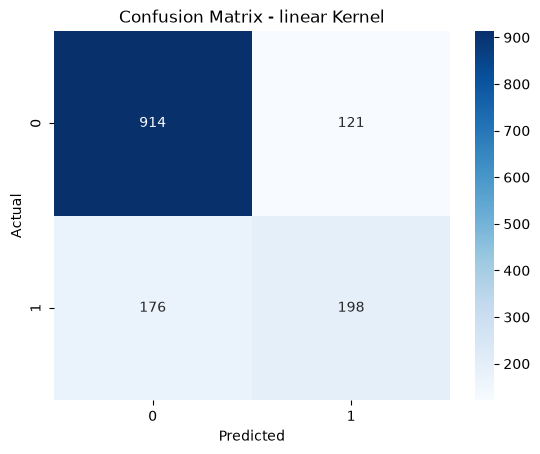

In [7]:
# F1 ke lihaz se behtareen kernel ka confusion matrix plot karein
best_kernel_name = results_df.loc[results_df['F1-Score'].idxmax(), 'Kernel']
print(f"Best Kernel based on F1-Score: {best_kernel_name}")

best_model = SVC(kernel=best_kernel_name, random_state=42)
best_model.fit(X_train_s, y_train)
y_pred_best = best_model.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_kernel_name} Kernel')
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:*

The linear kernel gave the best F1-score (0.5714), ahead of RBF (0.5562) and polynomial (0.5395). This does not surprise me much. After one-hot encoding the data has many binary features in about 30 dimensions, and in high dimensions a linear boundary is often already good enough. The three kernels are also very close (accuracy 0.789 to 0.793), so the extra flexibility of RBF/poly gave no real gain with default settings.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:*

The polynomial kernel used the most support vectors (2,739), then RBF (2,661) and linear (2,569). All of them use roughly half of the 5,634 training rows as support vectors. This means many points lie on or inside the margin, so the churn and non-churn classes overlap heavily. A higher count usually means a more complex boundary that depends on more training points and has a higher risk of overfitting.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:*

I will carry the RBF kernel forward. Its F1 (0.5562) is only 0.015 below linear, and it has the best accuracy (0.7928) and the best precision among the top two (0.6444). The linear kernel has no tunable parameters except C, but RBF has both C and gamma, so tuning can still improve it. Poly is the weakest on F1 (0.5395) and recall (0.4652) and also uses the most support vectors, so I drop it.

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", sum(pca.explained_variance_ratio_))

Explained Variance Ratio: [0.33246151 0.11980321]
Total Explained Variance: 0.4522647242767134


In [9]:
c_values = [0.01, 1, 100]
models_pca = {}

for c in c_values:
    clf = SVC(kernel='rbf', C=c, random_state=42)
    clf.fit(X_train_pca, y_train)
    models_pca[c] = clf
    print(f"C = {c}, Support Vectors Count: {clf.support_.shape[0]}")

C = 0.01, Support Vectors Count: 2997
C = 1, Support Vectors Count: 2659
C = 100, Support Vectors Count: 2631


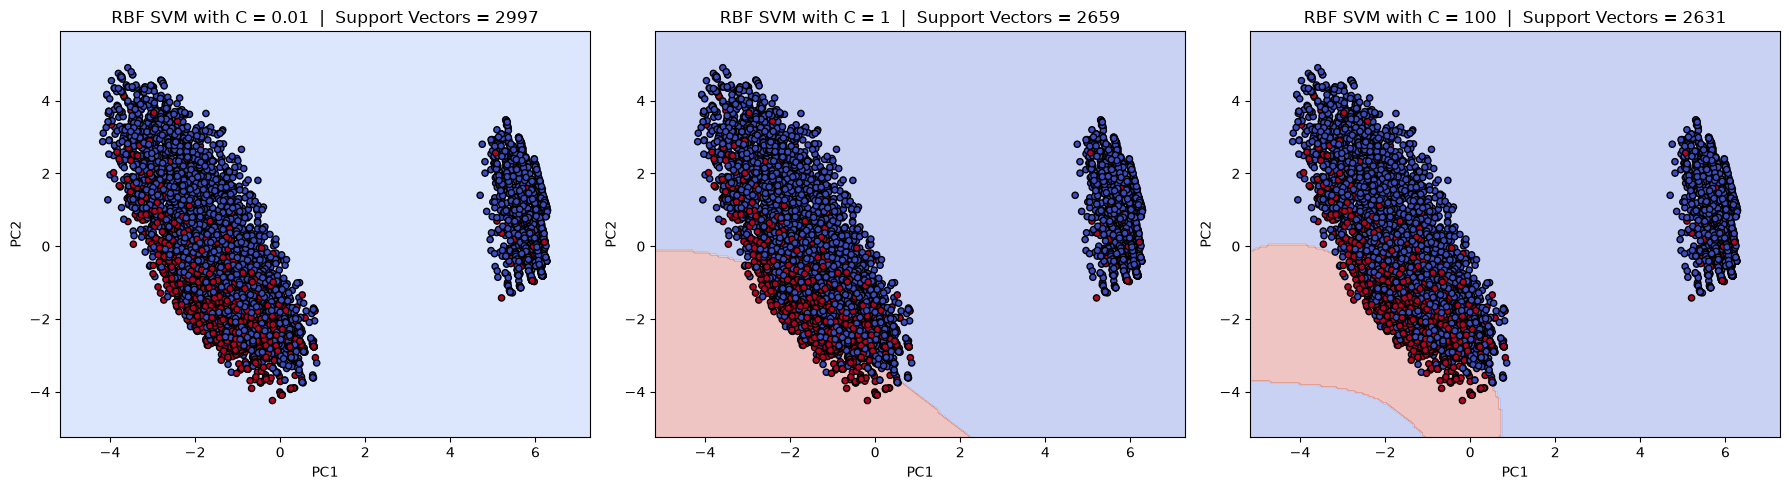

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grid points banane ke liye range set karein
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

for idx, c in enumerate(c_values):
    clf = models_pca[c]
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax = axes[idx]
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, edgecolors='k', cmap='coolwarm', s=20)
    ax.set_title(f"RBF SVM with C = {c}  |  Support Vectors = {clf.support_.shape[0]}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

**Plot interpretation:** The three panels show the same RBF-SVM trained on the 2-D PCA projection with C = 0.01, 1 and 100. With the smallest C the shaded regions are smooth and simple, with the largest C the boundary is more flexible. The red and blue points overlap heavily in all panels, because two PCA components keep only about 45% of the variance, so no value of C can separate the classes cleanly in this view.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:*

With C = 0.01 the boundary is very smooth and simple, and the classifier accepts many mistakes. With C = 1 it is somewhat more flexible. With C = 100 the model punishes every misclassified point heavily, so the boundary becomes more curved and bends around local groups of points. Because the classes overlap a lot in this 2-D view, the change is gradual and not dramatic.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:*

The number of support vectors went down as C went up: 2,997 (C=0.01), 2,659 (C=1) and 2,631 (C=100). This matches the theory. A small C allows many margin violations, so the margin is wide and many points end up inside it as support vectors. A large C gives a narrower margin and fewer support vectors. The drop is small (about 12%) because the classes overlap so much that many points stay on or inside the margin whatever C is.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting?

*Your answer:*

C = 100 is the closest to overfitting: it has the narrowest margin and the most flexible boundary, which tries to fit individual points and noise. C = 0.01 is the closest to underfitting: its boundary is too smooth and simple, so it ignores much of the structure and mostly favours the majority (no churn) class. C = 1 is a reasonable middle choice.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM?

*Your answer:*

The real model works in about 30 dimensions, but the plot uses only two PCA components, which keep only 45.2% of the variance (33.2% + 12.0%). More than half of the information is thrown away. Points that overlap in 2-D may be separable in the full space, so the plot can make the problem look harder than it is. The boundary shape and support-vector counts shown are for the 2-D model only, not for the real model, so the plot is only good for building intuition about C.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 0.01, 0.1, 1]
}

grid_search = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=5, scoring='f1')
grid_search.fit(X_train_s, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validated F1-Score:", grid_search.best_score_)

Best Parameters: {'C': 10, 'gamma': 0.01}
Best Cross-Validated F1-Score: 0.5852822456612709


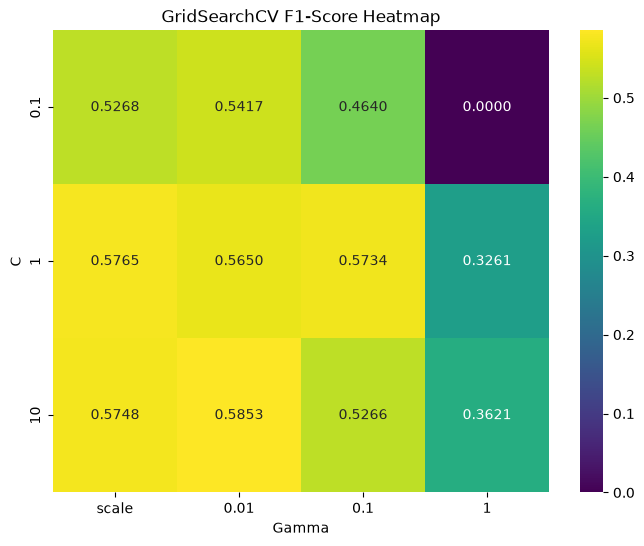

In [12]:
# Scores ko reshape karke heatmap banana
scores = grid_search.cv_results_['mean_test_score'].reshape(len(param_grid['C']), len(param_grid['gamma']))

plt.figure(figsize=(8, 6))
sns.heatmap(scores, annot=True, fmt='.4f', cmap='viridis',
            xticklabels=param_grid['gamma'], yticklabels=param_grid['C'])
plt.xlabel('Gamma')
plt.ylabel('C')
plt.title('GridSearchCV F1-Score Heatmap')
plt.show()

In [13]:
best_svm = grid_search.best_estimator_
y_pred_tuned = best_svm.predict(X_test_s)

print("Tuned Test Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Tuned Test Precision:", precision_score(y_test, y_pred_tuned))
print("Tuned Test Recall:", recall_score(y_test, y_pred_tuned))
print("Tuned Test F1-Score:", f1_score(y_test, y_pred_tuned))

Tuned Test Accuracy: 0.7885024840312278
Tuned Test Precision: 0.62751677852349
Tuned Test Recall: 0.5
Tuned Test F1-Score: 0.5565476190476191


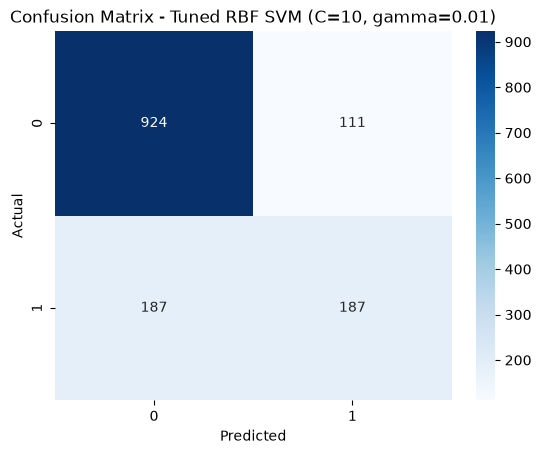

In [14]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Tuned RBF SVM (C=10, gamma=0.01)')
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:*

The best parameters were C = 10 and gamma = 0.01, with a cross-validated F1-score of 0.5853.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:*

There is no single sharp peak. The best cell (C=10, gamma=0.01) has several neighbouring cells with close scores, while a large gamma (1) clearly scores lower because it makes the model too wiggly and it overfits. This means the model is not very sensitive to the exact values, as long as gamma is not too large. One more point: the best C (10) is the largest value in my grid, so an even larger C might do slightly better.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:*

The cross-validated F1 was 0.5853 and the test F1 was 0.5565, a gap of about 0.03. This is small, so the tuned model generalises about as well as the CV estimate predicted. A large gap would suggest overfitting to the training data or the CV folds, or a test set that is different from the training data.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:*

The un-tuned RBF had test accuracy 0.7928 and F1 0.5562. The tuned model had accuracy 0.7885 and F1 0.5565. So tuning gave almost no improvement (F1 +0.0003) and accuracy dropped slightly. For F1 alone, tuning was not worth the extra computation. It did show that the default settings were already close to the best, and the real improvement came later from class_weight='balanced' in Part 5.

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [15]:
# Best parameters ke sath balanced model train karna
best_c = grid_search.best_params_['C']
best_gamma = grid_search.best_params_['gamma']

model_default = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight=None, probability=True, random_state=42)
model_balanced = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight='balanced', probability=True, random_state=42)

model_default.fit(X_train_s, y_train)
model_balanced.fit(X_train_s, y_train)

y_pred_def = model_default.predict(X_test_s)
y_pred_bal = model_balanced.predict(X_test_s)

print("--- Default Class Weight ---")
print(f"Precision: {precision_score(y_test, y_pred_def):.4f} | Recall: {recall_score(y_test, y_pred_def):.4f} | F1: {f1_score(y_test, y_pred_def):.4f}")

print("\n--- Balanced Class Weight ---")
print(f"Precision: {precision_score(y_test, y_pred_bal):.4f} | Recall: {recall_score(y_test, y_pred_bal):.4f} | F1: {f1_score(y_test, y_pred_bal):.4f}")

C:\Users\mubas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\mubas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- Default Class Weight ---
Precision: 0.6275 | Recall: 0.5000 | F1: 0.5565

--- Balanced Class Weight ---
Precision: 0.5070 | Recall: 0.7781 | F1: 0.6139


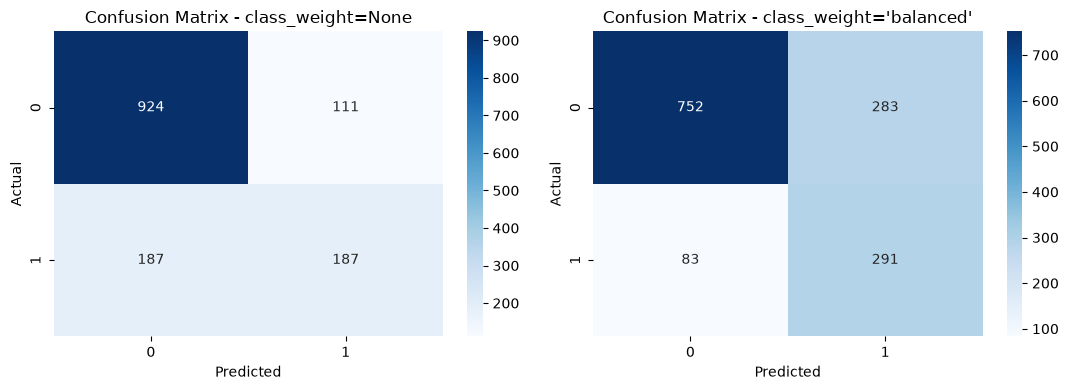

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, preds, title in zip(axes, [y_pred_def, y_pred_bal], ['class_weight=None', "class_weight='balanced'"]):
    sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'Confusion Matrix - {title}')
plt.tight_layout()
plt.show()

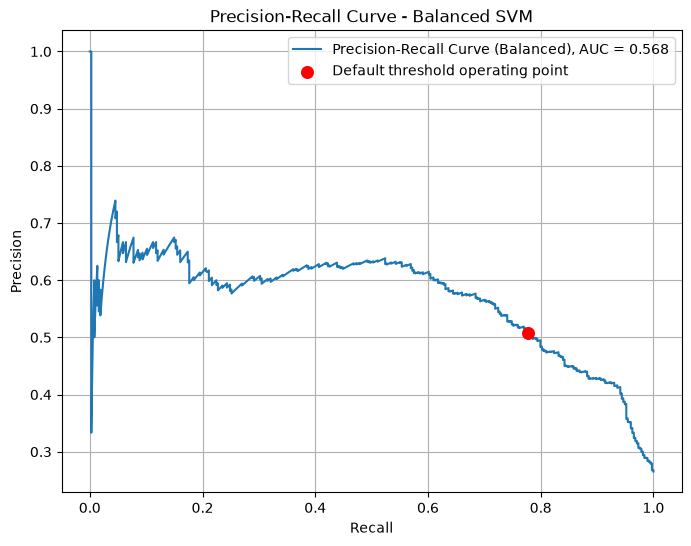

In [17]:
from sklearn.metrics import precision_recall_curve, auc

y_scores = model_balanced.decision_function(X_test_s)
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (Balanced), AUC = {auc(recall, precision):.3f}')
# operating point of the default decision threshold (decision score = 0, i.e. the 0.5 equivalent)
plt.scatter([recall_score(y_test, y_pred_bal)], [precision_score(y_test, y_pred_bal)],
            color='red', zorder=5, s=70, label='Default threshold operating point')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Balanced SVM')
plt.legend()
plt.grid(True)
plt.show()

**Plot interpretation:** The curve shows the usual trade-off: as recall goes up, precision comes down. The red dot is the default threshold of the balanced model (recall 0.778, precision 0.507). Moving the threshold along the curve would let the company choose more recall or more precision depending on its campaign budget.

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:*

Precision fell from 0.6275 to 0.5070 (-0.1205). Recall rose from 0.5000 to 0.7781 (+0.2781). F1 improved from 0.5565 to 0.6139 (+0.0574). The balanced model catches many more churners but also flags more loyal customers by mistake.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:*

Missing a real churner (false negative) is more costly. The company loses that customer's monthly revenue and has to spend much more to win a new customer than to keep an existing one. A false positive only costs a small retention offer (for example a discount) given to someone who would have stayed anyway. So I would deploy the balanced model, because it finds 77.8% of churners instead of 50.0%, even though its precision is lower.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:*

I had to set `probability=True` in `SVC()`. It fits an extra calibration step (Platt scaling, using internal 5-fold cross-validation), which makes training slower, and it allows `predict_proba()`. For the precision-recall curve I used `decision_function()` scores, and for the CSV file I used `predict_proba()`.

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Dusre models train karna taake comparison mukammal ho sakay
dt = DecisionTreeClassifier(random_state=42).fit(X_train_s, y_train)
rf = RandomForestClassifier(random_state=42).fit(X_train_s, y_train)
lr = LogisticRegression(random_state=42).fit(X_train_s, y_train)
knn = KNeighborsClassifier().fit(X_train_s, y_train)

models_dict = {
    'Decision Tree': dt,
    'Random Forest': rf,
    'Logistic Regression': lr,
    'KNN': knn,
    'Tuned SVM (Balanced)': model_balanced
}

comparison_data = []
for name, mdl in models_dict.items():
    preds = mdl.predict(X_test_s)
    comparison_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1-Score': f1_score(y_test, preds, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.740951,0.512535,0.491979,0.502046
1,Random Forest,0.785664,0.621622,0.491979,0.549254
2,Logistic Regression,0.806955,0.658385,0.566845,0.609195
3,KNN,0.747339,0.525281,0.500000,0.512329
4,Tuned SVM (Balanced),0.740241,0.506969,0.778075,0.613924


C:\Users\mubas\AppData\Local\Temp\ipykernel_20564\3012087462.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='F1-Score', data=comparison_df, palette='viridis')


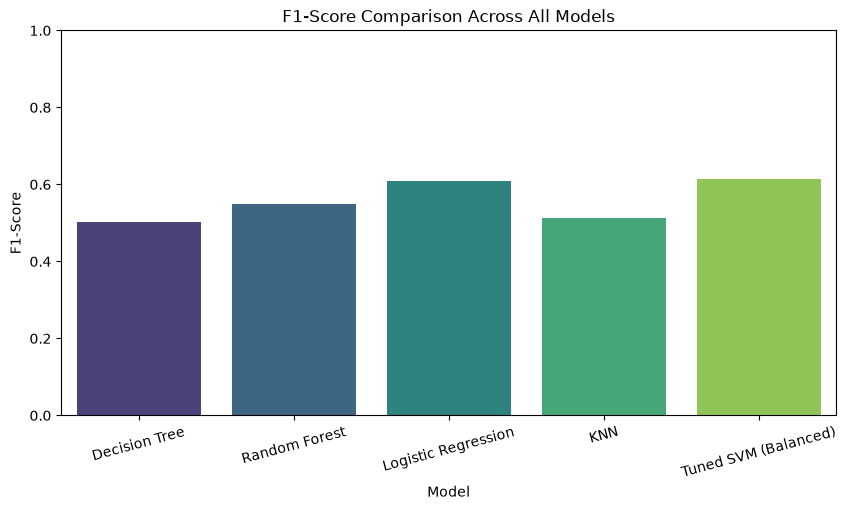

In [19]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Model', y='F1-Score', data=comparison_df, palette='viridis')
plt.title('F1-Score Comparison Across All Models')
plt.ylim(0, 1.0)
plt.xticks(rotation=15)
plt.show()

**Plot interpretation:** The bar chart compares F1-scores. Tuned SVM (0.614) and Logistic Regression (0.609) are clearly above Random Forest (0.549), KNN (0.512) and Decision Tree (0.502), but the gap between the top two is very small.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:*

The tuned SVM with balanced class weights wins on both F1-score (0.6139) and recall (0.7781), so they are the same model. Logistic Regression is a very close second on F1 (0.6092) and is the best on accuracy (0.8070) and precision (0.6584).

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:*

Yes, in this case it was worth it, mainly for recall. The SVM recall (0.778) is far above Random Forest (0.492), Decision Tree (0.492) and KNN (0.500), and its F1 is the highest. The cost is real though: grid search with 5-fold CV and probability=True makes SVM slow to train, and Logistic Regression gets almost the same F1 (0.609) in a fraction of the time.

(c) Which single model would you recommend deploying, and why?

*Your answer:*

I recommend the tuned balanced SVM (C=10, gamma=0.01). It has the best F1 (0.6139) and the best recall (0.7781), and for churn the main goal is to catch as many churners as possible. Its weaker points are lower precision (0.5070) and lower accuracy (0.7402) than Logistic Regression (0.6584 and 0.8070), so some retention offers will go to customers who would have stayed. If the company prefers a fast, simple and explainable model, Logistic Regression is a good alternative.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [20]:
# Final chosen model se predictions generate karke CSV save karna
final_preds = model_balanced.predict(X_test_s)
final_probs = model_balanced.predict_proba(X_test_s)[:, 1]

submission_df = pd.DataFrame({
    'True_Label': y_test.values,
    'Predicted_Label': final_preds,
    'Predicted_Probability': final_probs
})

submission_df.to_csv('svm_predictions.csv', index=False)
print("File 'svm_predictions.csv' successfully save ho gayi hai!")
display(submission_df.head())

File 'svm_predictions.csv' successfully save ho gayi hai!


,True_Label,Predicted_Label,Predicted_Probability
0,0,0,0.059810
1,0,1,0.690807
2,0,0,0.049898
3,0,1,0.431161
4,0,0,0.046058


**Executive Summary**

I chose the tuned RBF-kernel SVM with `class_weight='balanced'` (C=10, gamma=0.01, features scaled with StandardScaler) as the final churn model. On the test set it reached F1 = 0.6139, recall = 0.7781, precision = 0.5070 and accuracy = 0.7402, the best F1 and recall among the five models compared. Logistic Regression was very close on F1 (0.6092) and better on accuracy and precision. The main trade-off in Part 5 was giving up precision (0.6275 to 0.5070) to gain a lot of recall (0.5000 to 0.7781), because missing a churner costs more than sending a retention offer to a loyal customer. One limitation is that the comparison used a single train/test split and untuned Decision Tree/KNN/Logistic Regression models, so small F1 differences may not be significant. Also, the best C (10) was at the edge of my grid, so a wider search might give a slightly better model.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:*

Two things surprised me. Scaling the features alone raised accuracy from 65.3% to 78.9%, and hyperparameter tuning barely changed the F1-score (0.5562 to 0.5565), while simply using class_weight='balanced' raised recall from 0.50 to 0.78.

(b) If you had one more hour, what would you try next?

*Your answer:*

I would extend the grid to larger C values, tune the decision threshold directly on the precision-recall curve, and try SMOTE and feature engineering (for example tenure groups). I would also re-run Logistic Regression with class_weight='balanced' to make the model comparison fairer.